# XAUUSD Multiclass Prediction — Versi Optimasi
Window=96, Horizon=6 | 57 Fitur | Conv-GRU | TimeSeriesSplit CV + LR Finder

In [2]:
import torch
import MetaTrader5 as mt5
import datetime
import pandas as pd
import numpy as np

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

Device: cuda


In [3]:
if not mt5.initialize():
    print("Initialize gagal:", mt5.last_error())
    quit()
print("Berhasil Terhubung")

Berhasil Terhubung


## 1. Feature Engineering

In [4]:
from ta.volatility import BollingerBands
def add_ema(df):
    df["ema20"]  = df["close"].ewm(span=20).mean()
    df["ema50"]  = df["close"].ewm(span=50).mean()
    df["ema200"] = df["close"].ewm(span=200).mean()
    df["ema20_dist"]  = (df["close"] - df["ema20"])  / df["ema20"]
    df["ema50_dist"]  = (df["close"] - df["ema50"])  / df["ema50"]
    df["ema200_dist"] = (df["close"] - df["ema200"]) / df["ema200"]
    return df

def add_bb(df):

    bb = BollingerBands(df["close"], window=20)

    df["bb_upper"] = bb.bollinger_hband()
    df["bb_lower"] = bb.bollinger_lband()
    df["bb_middle"] = bb.bollinger_mavg()

    df["bb_position"] = (
        (df["close"]-df["bb_lower"]) /
        (df["bb_upper"]-df["bb_lower"]+1e-8)
    )

    return df

def add_macd(df):
    ema12 = df["close"].ewm(span=12).mean()
    ema26 = df["close"].ewm(span=26).mean()
    df["macd"]        = (ema12 - ema26) / df["close"]
    df["macd_signal"] = df["macd"].ewm(span=9).mean()
    return df

def add_rsi(df, period=14):
    # Hitung selisih close, pertahankan indeks asli df
    delta = df["close"].diff()
    
    # Gunakan np.where tetapi langsung bungkus dengan Series bernilai indeks sama dengan df
    gain = pd.Series(np.where(delta > 0, delta, 0.0), index=df.index)
    loss = pd.Series(np.where(delta < 0, -delta, 0.0), index=df.index)
    
    # Menggunakan Wilder's Exponential Moving Average (Sama seperti MT5/TradingView)
    # alpha=1/period adalah standar kalkulasi RSI Wilder
    avg_gain = gain.ewm(alpha=1/period, min_periods=period, adjust=False).mean()
    avg_loss = loss.ewm(alpha=1/period, min_periods=period, adjust=False).mean()
    
    rs = avg_gain / (avg_loss + 1e-9)
    df["rsi"] = 100 - (100 / (1 + rs))
    
    # Opsional: langsung normalisasi ke skala -1 s.d 1 agar Conv-GRU kamu lebih stabil
    df["rsi_norm"] = (df["rsi"] - 50) / 50
    
    return df

def add_atr(df, period=14):
    hl  = df["high"] - df["low"]
    hc  = np.abs(df["high"] - df["close"].shift())
    lc  = np.abs(df["low"]  - df["close"].shift())
    tr  = np.maximum(hl, np.maximum(hc, lc))
    df["atr"] = pd.Series(tr).rolling(period).mean()
    return df

def calculate_volume_profile_rolling(df, window=60, n_bins=10):
    """
    Menghitung jarak harga saat ini ke Point of Control (POC) berdasarkan Rolling Window.
    """
    poc_distances = np.zeros(len(df))
    
    # Konversi ke numpy array untuk kecepatan komputasi
    closes = df['close'].values
    volumes = df['tick_volume'].values
    
    for i in range(window, len(df)):
        # Ambil window historis
        window_closes = closes[i-window:i]
        window_volumes = volumes[i-window:i]
        
        # Buat Price Bins berdasarkan harga tertinggi dan terendah di window tersebut
        min_p, max_p = window_closes.min(), window_closes.max()
        if max_p == min_p:
            poc_distances[i] = 0
            continue
            
        bins = np.linspace(min_p, max_p, n_bins + 1)
        
        # Hitung volume digital (horizontal volume) per bin
        # Mencari tahu setiap close masuk ke bin mana
        bin_indices = np.digitize(window_closes, bins) - 1
        bin_indices = np.clip(bin_indices, 0, n_bins - 1)
        
        bin_volumes = np.zeros(n_bins)
        for idx, vol in zip(bin_indices, window_volumes):
            bin_volumes[idx] += vol
            
        # Temukan bin dengan volume terbesar (Point of Control / POC)
        poc_bin_idx = np.argmax(bin_volumes)
        # Ambil nilai tengah harga dari bin POC tersebut
        poc_price = (bins[poc_bin_idx] + bins[poc_bin_idx + 1]) / 2
        
        # Hitung jarak relatif % harga close saat ini ke POC
        poc_distances[i] = (closes[i] - poc_price) / poc_price
        
    return poc_distances

def calculate_price_density_rolling(df, window=120, tolerance_atr_mult=0.5):
    """
    Menghitung seberapa sering area harga saat ini dijadikan titik pantulan (High/Low) di masa lalu.
    """
    density_counts = np.zeros(len(df))
    
    closes = df['close'].values
    highs = df['high'].values
    lows = df['low'].values
    atrs = df['atr'].values  # Pastikan kamu sudah menghitung kolom 'atr' sebelumnya
    
    for i in range(window, len(df)):
        current_close = closes[i]
        current_atr = atrs[i]
        
        # Tentukan batas toleransi area S/R berdasarkan volatilitas (ATR)
        # Supaya dinamis mengikuti kondisi market XAUUSD
        buffer = current_atr * tolerance_atr_mult
        
        # Ambil data High dan Low historis dalam window
        window_highs = highs[i-window:i]
        window_lows = lows[i-window:i]
        
        # Hitung berapa banyak High/Low masa lalu yang nempel di harga Close saat ini
        high_hits = np.sum((window_highs >= current_close - buffer) & (window_highs <= current_close + buffer))
        low_hits = np.sum((window_lows >= current_close - buffer) & (window_lows <= current_close + buffer))
        
        # Total interaksi harga (Price Density)
        density_counts[i] = high_hits + low_hits
        
    # Normalisasi agar skalanya sehat masuk ke model (Z-Score rolling sederhana)
    # Atau bisa dibagi dengan 'window' agar menghasilkan rasio 0 sampai 1
    return density_counts / (window * 2)

def calculate_daily_anchors(df_intraday):
    """
    Menghitung High, Low, PP, R1, dan S1 dari hari sebelumnya (Yesterday).
    Asumsi: df_intraday memiliki DatetimeIndex.
    """
    # 1. Resample data intraday ke skala Harian (Daily)
    daily = df_intraday['close'].resample('D').ohlc()
    
    # Masukkan data High dan Low harian murni
    daily['high'] = df_intraday['high'].resample('D').max()
    daily['low'] = df_intraday['low'].resample('D').min()
    
    # Drop hari yang tidak ada transaksi (misal akhir pekan)
    daily = daily.dropna()
    
    # 2. Geser data (SHIFT 1) agar hari ini menggunakan data "HARI KEMARIN"
    # Ini krusial agar model tidak mencontek data hari ini!
    daily['prev_high'] = daily['high'].shift(1)
    daily['prev_low'] = daily['low'].shift(1)
    daily['prev_close'] = daily['close'].shift(1)
    
    # 3. Hitung Rumus Pivot Point Standar berdasarkan data kemarin
    daily['PP'] = (daily['prev_high'] + daily['prev_low'] + daily['prev_close']) / 3
    daily['R1'] = (2 * daily['PP']) - daily['prev_low']
    daily['S1'] = (2 * daily['PP']) - daily['prev_high']
    
    # Kita hanya butuh kolom jangkar ini saja
    anchor_columns = ['prev_high', 'prev_low', 'PP', 'R1', 'S1']
    return daily[anchor_columns]

def generate_anchor_distance_features(df):
    """
    Menggabungkan jangkar harian ke data intraday dan menghitung jarak relatif %.
    """
    # Pastikan index berbentuk datetime
    df.index = pd.to_datetime(df.index)
    
    # Buat kolom pembantu berupa 'tanggal' saja untuk merge
    df['date_key'] = df.index.date
    
    # Hitung jangkar harian
    daily_anchors = calculate_daily_anchors(df)
    daily_anchors.index = daily_anchors.index.date # Ubah index menjadi tanggal saja
    
    # Gabungkan (Merge) data intraday dengan data jangkar harian
    df = df.merge(daily_anchors, left_on='date_key', right_index=True, how='left')
    
    # Isu hari Senin: Karena shift(1) hari Minggu kosong, kita forward fill (ffill) jika ada bolong
    df[['prev_high', 'prev_low', 'PP', 'R1', 'S1']] = df[['prev_high', 'prev_low', 'PP', 'R1', 'S1']].ffill()
    
    # 4. HITUNG JARAK RELATIF (%)
    # Rumus: (Harga Sekarang - Harga Jangkar) / Harga Jangkar
    df['prev_day_high_dist'] = (df['close'] - df['prev_high']) / df['prev_high']
    df['prev_day_low_dist']  = (df['close'] - df['prev_low']) / df['prev_low']
    
    df['pivot_point_dist']   = (df['close'] - df['PP']) / df['PP']
    df['r1_dist']            = (df['close'] - df['R1']) / df['R1']
    df['s1_dist']            = (df['close'] - df['S1']) / df['S1']
    
    # Hapus kolom temporary agar dataset bersih kembali
    df = df.drop(columns=['date_key', 'prev_high', 'prev_low', 'PP', 'R1', 'S1'])
    
    # Isi data kosong di baris-baris awal dengan 0
    return df.fillna(0)

def calculate_volume_zscore(df, window=20):
    """
    Menghitung seberapa ekstrem volume saat ini dibanding rata-rata historisnya.
    """
    # 1. Hitung rata-rata rolling (Mean) dari volume
    roll_mean = df['tick_volume'].rolling(window=window).mean()
    
    # 2. Hitung standar deviasi rolling (Std Dev) dari volume
    roll_std = df['tick_volume'].rolling(window=window).std()
    
    # 3. Hitung Z-Score (tambahkan epsilon 1e-8 untuk menghindari pembagian dengan nol)
    volume_zscore = (df['tick_volume'] - roll_mean) / (roll_std + 1e-8)
    
    # Isi nilai NaN di awal window dengan 0
    return volume_zscore.fillna(0)

def calculate_atr_zscore(df, window=20):
    """
    Menghitung ekspansi atau kompresi volatilitas berdasarkan Z-Score dari ATR.
    Pastikan kolom 'atr' sudah ada di DataFrame kamu.
    """
    # 1. Hitung rata-rata rolling dari ATR
    roll_mean_atr = df['atr'].rolling(window=window).mean()
    
    # 2. Hitung standar deviasi rolling dari ATR
    roll_std_atr = df['atr'].rolling(window=window).std()
    
    # 3. Hitung Z-Score untuk mendeteksi spread expansion
    atr_zscore = (df['atr'] - roll_mean_atr) / (roll_std_atr + 1e-8)
    
    return atr_zscore.fillna(0)

def calculate_session_volume_zscore(df, window_days=20):
    """
    Menghitung Z-Score volume berdasarkan jam yang sama di hari-hari sebelumnya.
    Sangat kuat untuk menjinakkan bias waktu pada XAUUSD.
    """
    # Pastikan index berupa datetime
    df['hour_group'] = df.index.hour
    
    # Hitung rata-rata dan std dev per jam menggunakan transform rolling harian
    # Catatan: Asumsi data intraday lengkap. Pendekatan praktis:
    roll_mean = df.groupby('hour_group')['tick_volume'].transform(lambda x: x.rolling(window=window_days, min_periods=1).mean())
    roll_std = df.groupby('hour_group')['tick_volume'].transform(lambda x: x.rolling(window=window_days, min_periods=1).std())
    
    session_zscore = (df['tick_volume'] - roll_mean) / (roll_std + 1e-8)
    
    df = df.drop(columns=['hour_group'])
    return session_zscore.fillna(0)


def create_features(df):
    import numpy as np
    import pandas as pd

    # Returns
    df["return"] = df["close"].pct_change()
    df["ret_1"]  = df["close"].pct_change(1)
    df["ret_2"]  = df["close"].pct_change(2)
    df["ret_3"]  = df["close"].pct_change(3)
    df["ret_6"]  = df["close"].pct_change(6)
    df["ret_12"] = df["close"].pct_change(12)
    df["ret_24"] = df["close"].pct_change(24)

    df = add_rsi(df)
    df = add_atr(df)
    df = add_ema(df)
    df = add_bb(df)
    df = add_macd(df)

    # Volatility
    df["volatility"] = df["return"].rolling(20).std()

    # Candle pattern (normalized)
    df["body"]       = (df["close"] - df["open"]) / df["close"]
    df["upper_wick"] = (df["high"] - np.maximum(df["open"], df["close"])) / df["close"]
    df["lower_wick"] = (np.minimum(df["open"], df["close"]) - df["low"]) / df["close"]

    # Time encoding & Day encoding
    datetime_col = pd.to_datetime(df["time"], unit="s")
    hour = datetime_col.dt.hour
    day_of_week = datetime_col.dt.dayofweek # 0=Senin, 6=Minggu

    # 1. Sesi Asia (06:00 - 14:00)
    df["sesi_asia"] = ((hour >= 6) & (hour <= 14)).astype(int)

    # 2. Sesi Eropa/London (14:00 - 22:00)
    df["sesi_eropa"] = ((hour >= 14) & (hour <= 22)).astype(int)

    # 3. Sesi Amerika / NY (19:00 - 03:00) -> Menggunakan OR (|) karena menyeberang tengah malam
    df["sesi_amerika"] = ((hour >= 19) | (hour <= 3)).astype(int)

    # 4. Sesi Golden / Overlap London-NY (19:00 - 22:00) -> Sangat penting untuk XAUUSD
    df["sesi_golden"] = ((hour >= 19) & (hour <= 22)).astype(int)
    
    # Sine/Cosine Encoding untuk Jam (Siklus 24 Jam)
    df["hour_sin"] = np.sin(2 * np.pi * hour / 24)
    df["hour_cos"] = np.cos(2 * np.pi * hour / 24)

    # Sine/Cosine Encoding untuk Hari (Siklus 7 Hari - Sangat penting untuk anomali Senin/Jumat)
    df["day_sin"] = np.sin(2 * np.pi * day_of_week / 7)
    df["day_cos"] = np.cos(2 * np.pi * day_of_week / 7)

    # Momentum
    df["momentum_3"] = (df["close"] - df["close"].shift(3)) / df["close"]
    df["momentum_6"] = (df["close"] - df["close"].shift(6)) / df["close"]

    # Volume (hanya ratio — hapus vol_ma absolut)
    df["vol_ma"]    = df["tick_volume"].rolling(10).mean()
    df["vol_ratio"] = df["tick_volume"] / (df["vol_ma"] + 1e-9)

    # Bar strength
    df["bar_strength"] = np.abs(df["close"] - df["open"]) / (df["high"] - df["low"] + 1e-8)

    # Garman-Klass Volatility
    inside_sqrt = 0.5 * (np.log(df["high"] / df["low"])) ** 2 - (
        2 * np.log(2) - 1) * (np.log(df["close"] / df["open"])) ** 2
    df["vol_gk"] = np.sqrt(np.clip(inside_sqrt, 0, None))

    # Vol Z-Score (lookback 96)
    vol_m = df["vol_gk"].rolling(window=96).mean()
    vol_s = df["vol_gk"].rolling(window=96).std()
    df["vol_zscore"] = (df["vol_gk"] - vol_m) / (vol_s + 1e-8)

    # NATR = ATR (sudah / close di add_atr)
    df["natr"] = df["atr"] / df["close"]

    # Streak
    is_bull = (df["close"] > df["open"]).astype(int)
    is_bear = (df["close"] < df["open"]).astype(int)
    df["bull_streak"] = (is_bull.groupby((is_bull != is_bull.shift()).cumsum()).cumsum()) * is_bull
    df["bear_streak"] = (is_bear.groupby((is_bear != is_bear.shift()).cumsum()).cumsum()) * is_bear

    # Price position 96
    rolling_min = df["low"].rolling(window=96).min()
    rolling_max = df["high"].rolling(window=96).max()
    df["price_position_96"] = (df["close"] - rolling_min) / (rolling_max - rolling_min + 1e-8)

    # ── Divergence RSI ──
    df['rsi_slope']   = df['rsi'].diff(3)
    df['price_slope'] = df['close'].pct_change(3)
    df['rsi_div']     = df['rsi_slope'] - df['price_slope'] * 100

    # ── Volume Confirmation ──
    df['vol_confirm'] = df['vol_ratio'] * df['body']

    # ── ATR Ratio (volatility regime) ──
    df['atr_ratio'] = df['atr'] / df['atr'].rolling(50).mean()

    # ── Candle efficiency ──
    df['efficiency'] = (df['close'] - df['open']).abs() / \
                       (df['high'] - df['low'] + 1e-8)

    # ── Higher timeframe trend (simulasi dari M5) ──
    df['trend_1h'] = np.sign(df['close'] - df['close'].ewm(span=12).mean())
    df['trend_4h'] = np.sign(df['close'] - df['close'].ewm(span=48).mean())

    df['poc_dist'] = calculate_volume_profile_rolling(df, window=60, n_bins=10)

    df['price_density'] = calculate_price_density_rolling(df, window=120, tolerance_atr_mult=0.5)

    df = generate_anchor_distance_features(df)

    df['volume_zscore'] = calculate_volume_zscore(df, window=20)

    df['atr_zscore'] = calculate_atr_zscore(df, window=20)

    df['volume_zscore_modular'] = calculate_session_volume_zscore(df, window_days=14)

    # ── Perbaikan Rumus FVG Khusus Scalping (Konsisten Menggunakan Huruf Kecil) ──
    
    # 1. Hitung ATR (Volatilitas Lokal) untuk menyaring noise
    df['tr'] = np.maximum(df['high'] - df['low'], 
                          np.maximum((df['high'] - df['close'].shift(1)).abs(), 
                                     (df['low'] - df['close'].shift(1)).abs()))
    df['atr_14'] = df['tr'].rolling(window=14).mean()

    df['tr_percentage'] = df['tr'] / df['close']
    df['atr_14_percentage'] = df['atr_14'] / df['close']

    # 2. Rumus Bullish FVG (Sudut Pandang Candle Tengah t)
    df['bullish_fvg_gap'] = df['low'].shift(-1) - df['high'].shift(1)
    df['valid_scalp_fvg'] = ((df['bullish_fvg_gap'] > 0) & (df['bullish_fvg_gap'] > (df['atr_14'] * 0.5))).astype(int)
    
    # Koordinat absolut untuk Engine Eksekusi Bot
    df['entry_price'] = np.where(df['valid_scalp_fvg'] == 1, df['high'].shift(1), 0.0)
    df['bullish_sl'] = np.where(df['valid_scalp_fvg'] == 1, df['low'].shift(1), 0.0)

    # Fitur Jarak Relatif ke Bullish FVG (Untuk input model AI agar bebas kebocoran data)
    # Jika tidak ada FVG aktif, jarak diset ke 0
    df['bullish_fvg_dist'] = np.where(df['entry_price'] > 0, (df['close'] - df['entry_price']) / df['close'], 0.0)

    # 3. Rumus Bearish FVG (Sudut Pandang Candle Tengah t)
    df['bearish_fvg_gap'] = df['low'].shift(1) - df['high'].shift(-1)
    df['valid_scalp_bearish_fvg'] = ((df['bearish_fvg_gap'] > 0) & (df['bearish_fvg_gap'] > (df['atr_14'] * 0.5))).astype(int)
    
    # Koordinat absolut untuk Engine Eksekusi Bot
    df['bearish_entry_price'] = np.where(df['valid_scalp_bearish_fvg'] == 1, df['low'].shift(1), 0.0)
    df['bearish_stop_loss'] = np.where(df['valid_scalp_bearish_fvg'] == 1, df['high'], 0.0)

    # Fitur Jarak Relatif ke Bearish FVG (Untuk input model AI agar bebas kebocoran data)
    df['bearish_fvg_dist'] = np.where(df['bearish_entry_price'] > 0, (df['close'] - df['bearish_entry_price']) / df['close'], 0.0)

    # EMA slope
    df["ema20_slope"] = df["ema20"].pct_change(3)
    df["ema50_slope"] = df["ema50"].pct_change(5)
    df["ema200_slope"] = df["ema200"].pct_change(10)

    # EMA spread
    df["ema20_50"] = (df["ema20"]-df["ema50"])/df["atr"]
    df["ema50_200"] = (df["ema50"]-df["ema200"])/df["atr"]

    # Trend persistence
    df["trend_strength"] = abs(df["ema20"]-df["ema50"])/(df["atr"]+1e-8)

    lookback = 48

    df["swing_high"] = df["high"].rolling(lookback).max()
    df["swing_low"]  = df["low"].rolling(lookback).min()

    df["dist_high"] = (df["swing_high"]-df["close"])/(df["atr"]+1e-8)
    df["dist_low"]  = (df["close"]-df["swing_low"])/(df["atr"]+1e-8)

    df["rv12"] = df["return"].rolling(12).std()
    df["rv24"] = df["return"].rolling(24).std()
    df["rv48"] = df["return"].rolling(48).std()

    df["vol_term"] = df["rv12"]/df["rv48"]

    roll = df.close.rolling(48)

    df["z_close"] = (
    df.close-roll.mean()
    )/(roll.std()+1e-8)

    df["trend_regime"] = (
    df["trend_strength"]>1.5
    ).astype(int)

    df["vol_regime"] = (
    df["atr_ratio"]>1.3
    ).astype(int)

    df["range_regime"] = (
    df["price_position_96"].between(0.3,0.7)
    ).astype(int)

    swing_high = df["high"].rolling(48).max()
    swing_low = df["low"].rolling(48).min()

    df["dist_high"] = (
    swing_high-df["close"]
    )/(df["atr"]+1e-8)

    df["dist_low"] = (
    df["close"]-swing_low
    )/(df["atr"]+1e-8)

    df["rolling_trend"] = (
    df["ema20"]-df["ema50"]
    )/(df["atr"]+1e-8)

    df["trend_strength"] = (
    df["ema20"]-df["ema50"]
    ).abs()/(df["atr"]+1e-8)

    df["return_acceleration"] = df["ret_3"] - df["ret_12"]

    df["rsi_norm"] = (df["rsi"]-50)/50
    df["rsi_slope"] = df["rsi"].diff()
    df["macd_hist"] = df["macd"]-df["macd_signal"]

    df["swing_range"] = (
        df["dist_high"] +
        df["dist_low"]
    )

    df["volume_change"] = df["tick_volume"].pct_change()

    from ta.trend import ADXIndicator

    adx = ADXIndicator(
        high=df["high"],
        low=df["low"],
        close=df["close"],
        window=14
    )

    df["adx"] = adx.adx()
    df["+di"] = adx.adx_pos()
    df["-di"] = adx.adx_neg()

    df["adx"] = adx.adx()
    df["plus_di"] = adx.adx_pos()
    df["minus_di"] = adx.adx_neg()

    # =====================================================
    # Momentum Jangka Panjang
    # =====================================================
    
    df["ret_48"] = df["close"].pct_change(48)
    df["ret_96"] = df["close"].pct_change(96)
    
    # =====================================================
    # Trend Persistence
    # =====================================================
    
    df["trend_persistence"] = (
        (df["close"] > df["ema20"]).astype(int) +
        (df["ema20"] > df["ema50"]).astype(int) +
        (df["ema50"] > df["ema200"]).astype(int)
    )
    
    # =====================================================
    # Highest / Lowest Distance
    # =====================================================
    
    highest48 = df["high"].rolling(48).max()
    lowest48  = df["low"].rolling(48).min()
    
    df["dist_highest48"] = (highest48 - df["close"]) / df["atr"]
    df["dist_lowest48"]  = (df["close"] - lowest48) / df["atr"]
    
    # =====================================================
    # ATR Expansion
    # =====================================================
    
    df["atr_expand"] = df["atr"] / df["atr"].shift(10)
    
    # =====================================================
    # EMA Compression
    # =====================================================
    
    df["ema_compression"] = (
        (df["ema20"] - df["ema50"]).abs() /
        df["atr"]
    )
    
    # =====================================================
    # RSI Velocity
    # =====================================================
    
    df["rsi_velocity"] = df["rsi"].diff()
    df["rsi_acceleration"] = df["rsi_velocity"].diff()
    
    # =====================================================
    # Bollinger Width Change
    # =====================================================
    
    bb_width = (df["bb_upper"] - df["bb_lower"]) / df["bb_middle"]
    
    df["bb_width"] = bb_width
    df["bb_width_change"] = bb_width.pct_change()
    
    # =====================================================
    # Candle Strength
    # =====================================================
    
    range_ = (df["high"] - df["low"]).replace(0, np.nan)
    
    df["body_ratio"] = (
        (df["close"] - df["open"]).abs() / range_
    )
    
    df["bull_strength"] = (
        (df["close"] - df["low"]) / range_
    )
    
    df["bear_strength"] = (
        (df["high"] - df["close"]) / range_
    )
    
    # =====================================================
    # Volatility Rank
    # =====================================================
    
    df["volatility_rank"] = (
        df["volatility"]
        .rolling(200)
        .rank(pct=True)
    )
    
    # =====================================================
    # Breakout Strength
    # =====================================================
    
    highest20 = df["high"].rolling(20).max()
    lowest20  = df["low"].rolling(20).min()
    
    df["breakout_up"] = (
        df["close"] - highest20.shift(1)
    ) / df["atr"]
    
    df["breakout_down"] = (
        lowest20.shift(1) - df["close"]
    ) / df["atr"]
    
    # =====================================================
    # Price Position 200
    # =====================================================
    
    highest200 = df["high"].rolling(200).max()
    lowest200  = df["low"].rolling(200).min()
    
    df["price_position200"] = (
        (df["close"] - lowest200) /
        (highest200 - lowest200)
    )
    
    # =====================================================
    # Volume Momentum
    # =====================================================
    
    df["volume_momentum"] = (
        df["tick_volume"] /
        df["tick_volume"].rolling(20).mean()
    )
    
    # =====================================================
    # Momentum Acceleration
    # =====================================================
    
    df["momentum_acc"] = (
        df["ret_12"] -
        df["ret_48"]
    )


    bb_width = (
        (df["bb_upper"] - df["bb_lower"]) /
        df["bb_middle"]
    )
    
    df["bb_width"] = bb_width
    df["bb_width_change"] = bb_width.pct_change()

    # Menghapus NaN yang dihasilkan oleh rolling MA di awal-awal baris data (bukan kolom FVG)
    df = df.dropna(subset=['volatility', 'vol_zscore', 'atr_ratio', 'price_position_96'])
    df = df.dropna()

    df = df.copy(deep=True)
    
    return df

## 2. Load Data

In [4]:
from dateutil.relativedelta import relativedelta

symbol    = "XAUUSD"
timeframe = mt5.TIMEFRAME_M5
start     = datetime.datetime(2020, 1, 1)
end       = datetime.datetime.now()

all_data = []
cur = start
while cur < end:
    nxt   = cur + relativedelta(months=1)
    rates = mt5.copy_rates_range(symbol, timeframe, cur, nxt)
    if rates is not None and len(rates) > 0:
        all_data.append(pd.DataFrame(rates))
    else:
        print("Data kosong:", cur)
    cur = nxt

final_df = pd.concat(all_data, ignore_index=True)
print("Total candle:", len(final_df))
print("Range:", pd.to_datetime(final_df['time'].min(), unit='s'),
      "→", pd.to_datetime(final_df['time'].max(), unit='s'))
print(final_df.head())

Total candle: 457665
Range: 2019-12-31 17:00:00 → 2026-06-30 02:25:00
         time     open     high      low    close  tick_volume  spread  \
0  1577811600  1518.61  1520.58  1517.61  1520.39          612      13   
1  1577811900  1520.33  1521.07  1519.48  1519.68          533      16   
2  1577812200  1519.69  1521.49  1519.67  1521.35          392      17   
3  1577812500  1521.31  1521.87  1520.74  1521.79          312      14   
4  1577812800  1521.79  1521.88  1521.35  1521.80          277      13   

   real_volume  
0            0  
1            0  
2            0  
3            0  
4            0  


In [5]:
df = create_features(final_df.copy())
print("Setelah feature engineering:", len(df), "rows")
# 1. Atur pandas agar menampilkan semua kolom (None artinya tidak ada batasan)
pd.set_option('display.max_columns', None)

# 2. Jika kolomnya sangat panjang dan kamu ingin teks di dalamnya tidak terpotong:
pd.set_option('display.max_colwidth', None)
print(df.tail())
print(df.columns)

C:\Users\ANDRA\AppData\Local\Temp\ipykernel_15980\4126698795.py:461: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["rolling_trend"] = (
C:\Users\ANDRA\AppData\Local\Temp\ipykernel_15980\4126698795.py:469: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["return_acceleration"] = df["ret_3"] - df["ret_12"]
C:\Users\ANDRA\AppData\Local\Temp\ipykernel_15980\4126698795.py:473: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider 

Setelah feature engineering: 457427 rows
                                     time     open     high      low    close  \
1970-01-01 00:00:00.000457659  1782784800  4014.54  4018.36  4014.09  4017.79   
1970-01-01 00:00:00.000457660  1782785100  4017.85  4021.29  4017.71  4019.27   
1970-01-01 00:00:00.000457661  1782785400  4019.32  4021.39  4019.32  4020.75   
1970-01-01 00:00:00.000457662  1782785700  4020.74  4022.32  4020.47  4021.08   
1970-01-01 00:00:00.000457663  1782786000  4021.23  4021.39  4018.16  4018.40   

                               tick_volume  spread  real_volume    return  \
1970-01-01 00:00:00.000457659          619      34            0  0.000924   
1970-01-01 00:00:00.000457660          511      34            0  0.000368   
1970-01-01 00:00:00.000457661          551      34            0  0.000368   
1970-01-01 00:00:00.000457662          470      34            0  0.000082   
1970-01-01 00:00:00.000457663          484      34            0 -0.000666   

         

## 3. Dataset Creation

In [7]:
# === KONFIGURASI UTAMA ===
WINDOW_SIZE = 96
HORIZON     = 10    # A1: 6→24 bar (30 mnt → 2 jam) — label lebih bersih

# Hanya fitur yang sudah normalized — tidak ada harga/volume absolut
FEATURE_COLUMNS = [

    # ======================================================
    # RETURNS
    # ======================================================
    'return',
    'ret_2',
    'ret_3',
    'ret_6',
    'ret_12',
    'ret_24',
    'return_acceleration',

    # ======================================================
    # TREND
    # ======================================================
    'ema20_dist',
    'ema50_dist',
    'ema200_dist',

    'ema20_slope',
    'ema50_slope',
    'ema200_slope',

    'ema20_50',
    'ema50_200',
    
    'trend_strength',

    # ======================================================
    # MOMENTUM
    # ======================================================
    'rsi_norm',
    'rsi_slope',

    'macd',
    'macd_signal',
    'macd_hist',

    # ======================================================
    # VOLATILITY
    # ======================================================
    'natr',

    'volatility',
    'vol_gk',

    'atr_ratio',
    'atr_zscore',

    'rv12',
    'rv24',
    'rv48',

    'vol_term',

    'tr_percentage',

    # ======================================================
    # MARKET STRUCTURE
    # ======================================================
    'price_position_96',

    'dist_high',
    'dist_low',

    'swing_range',

    'z_close',

    'bb_position',

    # ======================================================
    # CANDLE
    # ======================================================
    'body',
    'upper_wick',
    'lower_wick',

    'bar_strength',

    # ======================================================
    # VOLUME
    # ======================================================
    'vol_ratio',
    'vol_confirm',

    'volume_change',

    'volume_zscore',
    'volume_zscore_modular',

    # ======================================================
    # MARKET PROFILE
    # ======================================================
    'poc_dist',
    'price_density',

    # ======================================================
    # DIVERGENCE
    # ======================================================
    'rsi_div',

    # ======================================================
    # FAIR VALUE GAP
    # ======================================================
    'valid_scalp_fvg',
    'valid_scalp_bearish_fvg',

    'bullish_fvg_dist',
    'bearish_fvg_dist',

    # ======================================================
    # SESSION
    # ======================================================
    'sesi_asia',
    'sesi_eropa',
    'sesi_amerika',
    'sesi_golden',

    # ======================================================
    # CYCLICAL TIME
    # ======================================================
    'hour_sin',
    'hour_cos',

    'day_sin',
    'day_cos',

    #
    #
    #
    'adx',
    'plus_di',
    'minus_di',
        # ===== Momentum tambahan =====
    'ret_48',
    'ret_96',

    # ===== Trend =====
    'trend_persistence',

    # ===== Market Structure =====

    # ===== ATR =====
    'atr_expand',

    # ===== RSI =====F
    'rsi_acceleration',

    # ===== Bollinger =====
    'bb_width',
    'bb_width_change',

    # ===== Candle =====
    'body_ratio',
    'bull_strength',
    'bear_strength',

    # ===== Volatility =====
    'volatility_rank',

    # ===== Breakout =====
    'breakout_up',
    'breakout_down',

    # ===== Position =====
    'price_position200',

    # ===== Volume =====
    'volume_momentum',

    # ===== Momentum =====
    'momentum_acc',
]
N_FEATURES = len(FEATURE_COLUMNS)
print(f"Jumlah fitur: {N_FEATURES}")


Jumlah fitur: 80


In [12]:
import numpy as np

def create_dataset_v2(data, window_size, horizon, pt_sl=[2.0, 2.0]):
    """
    A1: pt_sl=[2.0,2.0] + HORIZON=24 → label lebih bersih.
    Return:
      X      — fitur window (n, window, features)
      y      — label 3-class: 0=HOLD, 1=BUY, 2=SELL
      y_buy  — label binary: 1=BUY, 0=bukan BUY  (untuk model C3-BUY)
      y_sell — label binary: 1=SELL, 0=bukan SELL (untuk model C3-SELL)
      natr_arr — nilai NATR per sampel (untuk regime filter C2)
      adx_arr  — nilai ADX per sampel  (untuk regime filter C2, jika ada)
    """
    close   = data["close"].values
    natr    = data["natr"].values
    feats   = data[FEATURE_COLUMNS].values.astype(np.float32)
    # ADX proxy: gunakan atr_ratio kalau ADX tidak ada di FEATURE_COLUMNS
    adx_col = "adx" if "adx" in data.columns else "atr_ratio"
    adx_val = data[adx_col].values

    X, y, y_buy, y_sell = [], [], [], []
    natr_arr, adx_arr   = [], []

    for i in range(len(feats) - window_size - horizon):
        X.append(feats[i : i + window_size])

        idx_current   = i + window_size - 1
        current_price = close[idx_current]
        current_natr  = natr[idx_current]

        natr_arr.append(current_natr)
        adx_arr.append(adx_val[idx_current])

        if np.isnan(current_natr) or current_natr <= 0:
            y.append(0); y_buy.append(0); y_sell.append(0)
            continue

        upper_barrier = current_price * (1 + pt_sl[0] * current_natr)
        lower_barrier = current_price * (1 - pt_sl[1] * current_natr)

        label = 0
        for fut_p in close[idx_current + 1 : idx_current + horizon + 1]:
            if fut_p >= upper_barrier:
                label = 1; break
            elif fut_p <= lower_barrier:
                label = 2; break
        y.append(label)
        y_buy.append(1 if label == 1 else 0)
        y_sell.append(1 if label == 2 else 0)

    return (
        np.array(X,        dtype=np.float32),
        np.array(y,        dtype=np.int64),
        np.array(y_buy,    dtype=np.int64),
        np.array(y_sell,   dtype=np.int64),
        np.array(natr_arr, dtype=np.float32),
        np.array(adx_arr,  dtype=np.float32),
    )

# A1: pt_sl=[2.0,2.0], HORIZON=24
X, y, y_buy, y_sell, natr_arr, adx_arr = create_dataset_v2(
    df, WINDOW_SIZE, HORIZON, pt_sl=[1.5, 1.5]
)

unique, counts = np.unique(y, return_counts=True)
total = len(y)
print(f"Total sampel: {total}")
for lbl, cnt in zip(unique, counts):
    names = {0: "HOLD", 1: "BUY", 2: "SELL"}
    print(f"  {names[lbl]}: {cnt} ({cnt/total*100:.1f}%)")
print(f"X shape: {X.shape}")
print(f"BUY binary positif : {y_buy.sum():,}")
print(f"SELL binary positif: {y_sell.sum():,}")


Total sampel: 457321
  HOLD: 158770 (34.7%)
  BUY: 151054 (33.0%)
  SELL: 147497 (32.3%)
X shape: (457321, 96, 80)
BUY binary positif : 151,054
SELL binary positif: 147,497


In [13]:
print(pd.Series(y).value_counts())
print(pd.Series(y).value_counts(normalize=True))

0    158770
1    151054
2    147497
Name: count, dtype: int64
0    0.347174
1    0.330302
2    0.322524
Name: proportion, dtype: float64


In [14]:
print(df["natr"].describe())

for th in [0.001, 0.002, 0.003, 0.005, 0.008]:
    pct = (df["natr"] > th).mean() * 100
    print(f"NATR > {th:.3f}: {pct:.2f}%")

count    457427.000000
mean          0.000819
std           0.000589
min           0.000084
25%           0.000469
50%           0.000661
75%           0.000992
max           0.015503
Name: natr, dtype: float64
NATR > 0.001: 24.61%
NATR > 0.002: 3.68%
NATR > 0.003: 1.00%
NATR > 0.005: 0.20%
NATR > 0.008: 0.03%


In [15]:
for t in [0.0005, 0.0006, 0.0007, 0.0008, 0.0009, 0.0010, 0.0012]:
    pct = (df["natr"] > t).mean() * 100
    print(f"NATR > {t:.4f}: {pct:.2f}%")

NATR > 0.0005: 70.84%
NATR > 0.0006: 57.47%
NATR > 0.0007: 45.90%
NATR > 0.0008: 37.01%
NATR > 0.0009: 30.16%
NATR > 0.0010: 24.61%
NATR > 0.0012: 16.45%


## 4. Times Array & Scaler

Buat array timestamp per sampel.  
Scaler di-fit hanya pada data 2023–2025 (sebelum 2026).

In [16]:
from sklearn.preprocessing import RobustScaler
import joblib

times_raw   = pd.to_datetime(df['time'].values, unit='s')
times_array = times_raw[WINDOW_SIZE - 1 : len(df) - HORIZON - 1]
assert len(times_array) == len(X), f"Mismatch! {len(times_array)} vs {len(X)}"

print(f"Periode data X: {times_array[0]} → {times_array[-1]}")
print(f"Jumlah sampel : {len(times_array)} ✅")

cutoff_scaler = pd.Timestamp('2026-01-01')
scaler_end    = int(np.searchsorted(times_array, cutoff_scaler))

X_flat_train = X[:scaler_end].reshape(-1, N_FEATURES)
scaler_X     = RobustScaler()
scaler_X.fit(X_flat_train)
del X_flat_train

X_scaled = scaler_X.transform(X.reshape(-1, N_FEATURES)).reshape(X.shape)
joblib.dump(scaler_X, "scaler.pkl")
print(f"Scaler fit pada {scaler_end:,} sampel")

X_tensor      = torch.tensor(X_scaled,  dtype=torch.float32)
y_tensor      = torch.tensor(y,         dtype=torch.int64)
y_buy_tensor  = torch.tensor(y_buy,     dtype=torch.int64)    # C3
y_sell_tensor = torch.tensor(y_sell,    dtype=torch.int64)    # C3
natr_tensor   = torch.tensor(natr_arr,  dtype=torch.float32)  # C2
adx_tensor    = torch.tensor(adx_arr,   dtype=torch.float32)  # C2

print("Tensor siap.")
print(f"  X_tensor      : {X_tensor.shape}")
print(f"  y_buy_tensor  : {y_buy_tensor.shape}  positif={y_buy_tensor.sum().item():,}")
print(f"  y_sell_tensor : {y_sell_tensor.shape}  positif={y_sell_tensor.sum().item():,}")


Periode data X: 2020-01-02 22:30:00 → 2026-06-30 01:25:00
Jumlah sampel : 457321 ✅
Scaler fit pada 422,853 sampel
Tensor siap.
  X_tensor      : torch.Size([457321, 96, 80])
  y_buy_tensor  : torch.Size([457321])  positif=151,054
  y_sell_tensor : torch.Size([457321])  positif=147,497


## 5. Time-Series Cross-Validation (TimeSeriesSplit)

Menggunakan `TimeSeriesSplit` dari sklearn — train selalu sebelum val, tanpa data leakage.  
Tidak ada purge manual; sklearn sudah memastikan urutan temporal.

In [17]:
from sklearn.model_selection import TimeSeriesSplit

N_SPLITS = 2  # jumlah fold

tscv = TimeSeriesSplit(n_splits=N_SPLITS)

folds = []
for k, (train_idx, val_idx) in enumerate(tscv.split(X_tensor)):
    fold_info = {
        'fold'           : k + 1,
        'train_idx'      : train_idx,
        'val_idx'        : val_idx,
        'val_start_time' : times_array[val_idx[0]],
        'val_end_time'   : times_array[val_idx[-1]],
        'n_train'        : len(train_idx),
        'n_val'          : len(val_idx),
    }
    folds.append(fold_info)

    print(f"Fold {k+1}:")
    print(f"  Train : {len(train_idx):>7,} sampel  "
          f"[{times_array[train_idx[0]].strftime('%Y-%m-%d')} → "
          f"{times_array[train_idx[-1]].strftime('%Y-%m-%d')}]")
    print(f"  Val   : {len(val_idx):>7,} sampel  "
          f"[{times_array[val_idx[0]].strftime('%Y-%m-%d')} → "
          f"{times_array[val_idx[-1]].strftime('%Y-%m-%d')}]\n")

print(f"Total fold: {len(folds)}")


Fold 1:
  Train : 152,441 sampel  [2020-01-02 → 2022-03-03]
  Val   : 152,440 sampel  [2022-03-03 → 2024-05-02]

Fold 2:
  Train : 304,881 sampel  [2020-01-02 → 2024-05-02]
  Val   : 152,440 sampel  [2024-05-02 → 2026-06-30]

Total fold: 2


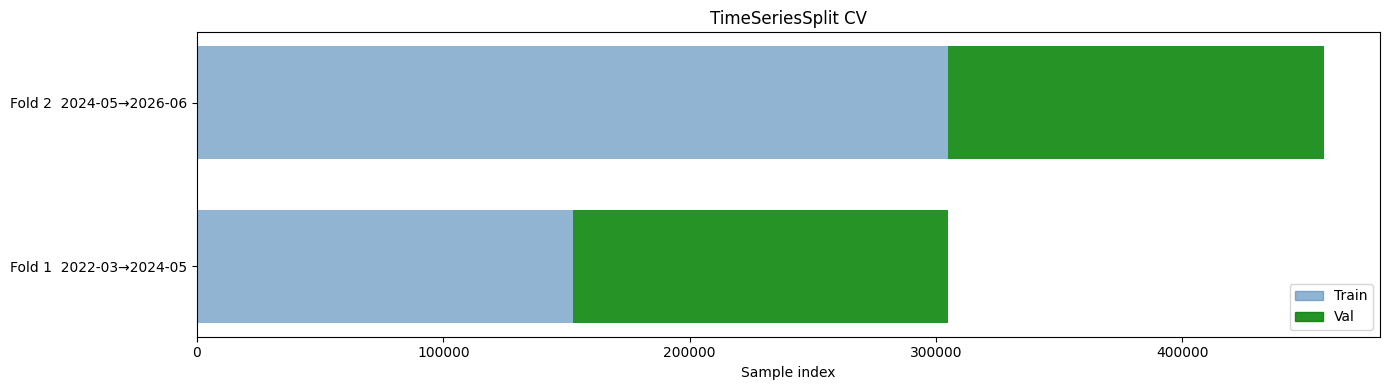

In [18]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

fig, ax = plt.subplots(figsize=(14, 4))
n = len(X_tensor)

for i, fold in enumerate(folds):
    y_pos  = i * 1.3
    tr_s   = fold['train_idx'][0]
    tr_e   = fold['train_idx'][-1]
    val_s  = fold['val_idx'][0]
    val_e  = fold['val_idx'][-1]

    ax.barh(y_pos, tr_e - tr_s,    left=tr_s,  height=0.9, color='steelblue', alpha=0.6)
    ax.barh(y_pos, val_e - val_s,  left=val_s, height=0.9, color='green',     alpha=0.85)

ax.set_yticks([i * 1.3 for i in range(len(folds))])
ax.set_yticklabels([
    f"Fold {f['fold']}  "
    f"{f['val_start_time'].strftime('%Y-%m')}→{f['val_end_time'].strftime('%Y-%m')}"
    for f in folds
])
ax.set_xlabel("Sample index")
ax.set_title("TimeSeriesSplit CV")
legend = [
    mpatches.Patch(color='steelblue', alpha=0.6,  label='Train'),
    mpatches.Patch(color='green',     alpha=0.85, label='Val'),
]
ax.legend(handles=legend, loc='lower right')
plt.tight_layout()
plt.show()


## 6. Model — Conv + GRU

In [19]:
# import torch
# import torch.nn as nn
# import torch.nn.functional as F

# class XAUSSDModel(nn.Module):
#     def __init__(self, n_features=60, n_classes=3, lookback=128,
#                  conv_ch=64,         # Diperkecil dari 256 agar tidak overfitting noise
#                  gru_hidden=128,     # Diperkecil dari 512 demi stabilitas data finansial
#                  gru_layers=1,       # 2 Layers sudah sangat cukup untuk menangkap temporal tren
#                  dropout=0.5):       
#         super().__init__()

#         self.conv_ch = conv_ch
#         self.gru_hidden = gru_hidden

#         # 1. Input Normalization khusus untuk menjaga stabilitas sekuensial
#         self.input_norm = nn.LayerNorm(n_features)

#         # 2. Pemrosesan Spasial/Lokal (Eksplorasi Fitur Antar Kolom)
#         self.conv = nn.Sequential(
#             nn.Conv1d(n_features, conv_ch, kernel_size=5, padding=2),
#             nn.BatchNorm1d(conv_ch), 
#             nn.GELU(), 
#             nn.Dropout(dropout * 0.5),
            
#             nn.Conv1d(conv_ch, conv_ch * 2, kernel_size=3, padding=1),
#             nn.BatchNorm1d(conv_ch * 2), 
#             nn.GELU(), 
#             nn.Dropout(dropout * 0.5),
            
#             nn.Conv1d(conv_ch * 2, conv_ch * 2, kernel_size=3, padding=1),
#             nn.BatchNorm1d(conv_ch * 2), 
#             nn.GELU(),
#         )

#         # 3. Pemrosesan Temporal (Arah Tren Waktu)
#         self.gru = nn.GRU(
#             input_size=conv_ch * 2,
#             hidden_size=gru_hidden,
#             num_layers=gru_layers,
#             batch_first=True,
#             dropout=dropout if gru_layers > 1 else 0.0
#         )

#         # 4. Positional Embedding dimasukkan sebagai Parameter terdaftar yang fleksibel
#         self.pos_embedding = nn.Parameter(torch.randn(1, lookback, gru_hidden))

#         # 5. Mekanisme Atensi Konteks Global
#         self.attention = nn.MultiheadAttention(embed_dim=gru_hidden, num_heads=4, batch_first=True, dropout=dropout)

#         # 6. Classifier Head (Prediksi Akhir Kelas Trading: HOLD, BUY, SELL)
#         self.head = nn.Sequential(
#             nn.LayerNorm(gru_hidden),
#             nn.Dropout(dropout),
#             nn.Linear(gru_hidden, 64), # Diperkecil ke 32 untuk kompresi akhir yang ketat
#             nn.GELU(),  
#             nn.Dropout(dropout),
#             nn.Linear(64, n_classes)
#         )

#     def forward(self, x):
#         # x shape awal: [Batch, Lookback, Features]
#         x = self.input_norm(x)
        
#         # Permute untuk Conv1D: [Batch, Features, Lookback]
#         x = self.conv(x.permute(0, 2, 1))
        
#         # Kembalikan ke format sekuensial: [Batch, Lookback, Conv_Ch * 2]
#         x = x.permute(0, 2, 1)
        
#         # Masuk ke GRU
#         x, _ = self.gru(x) # Output shape: [Batch, Lookback, GRU_Hidden]
        
#         # ── PERBAIKAN: Tambahkan Positional Embedding SEBELUM masuk Attention ──
#         # Ambil indeks posisi sesuai dimensi sekuens x secara dinamis
#         x = x + self.pos_embedding[:, :x.size(1), :]
        
#         # Masuk ke Multihead Attention dengan Residual Connection
#         attn_out, _ = self.attention(query=x, key=x, value=x)
#         x = x + attn_out
        
#         # Ambil hanya langkah waktu TERAKHIR (Candle paling baru tertutup) untuk prediksi masa depan
#         out = self.head(x[:, -1, :]) # Shape hasil: [Batch, N_Classes]
#         return out

# torch.manual_seed(42)
# model_1 = XAUSSDModel(n_features=N_FEATURES).to(device)
# n_params = sum(p.numel() for p in model_1.parameters() if p.requires_grad)
# print(f"Parameter: {n_params:,}")  # harusnya ~200K, jauh lebih kecil

In [20]:
# import torch
# import torch.nn as nn


# # ===========================
# # Residual CNN Block
# # ===========================
# class ResidualBlock(nn.Module):
#     def __init__(self, channels):
#         super().__init__()

#         self.block = nn.Sequential(
#             nn.Conv1d(channels, channels, kernel_size=3, padding=1),
#             nn.BatchNorm1d(channels),
#             nn.GELU(),

#             nn.Conv1d(channels, channels, kernel_size=3, padding=1),
#             nn.BatchNorm1d(channels)
#         )

#         self.act = nn.GELU()

#     def forward(self, x):
#         return self.act(self.block(x) + x)


# # ===========================
# # Trading Model
# # ===========================
# class TradingModel(nn.Module):

#     def __init__(self,
#                  n_features=58,
#                  n_classes=3):

#         super().__init__()

#         # CNN Encoder
#         self.cnn = nn.Sequential(

#             nn.Conv1d(
#                 in_channels=n_features,
#                 out_channels=64,
#                 kernel_size=3,
#                 padding=1
#             ),
#             nn.BatchNorm1d(64),
#             nn.GELU(),

#             ResidualBlock(64),

#             nn.Conv1d(
#                 64,
#                 128,
#                 kernel_size=5,
#                 padding=2
#             ),
#             nn.BatchNorm1d(128),
#             nn.GELU(),

#             nn.Dropout(0.2)
#         )

#         # BiGRU
#         self.gru = nn.GRU(
#             input_size=128,
#             hidden_size=128,
#             num_layers=2,
#             batch_first=True,
#             bidirectional=True,
#             dropout=0.2
#         )

#         # MultiHead Attention
#         self.attention = nn.MultiheadAttention(
#             embed_dim=256,
#             num_heads=4,
#             batch_first=True,
#             dropout=0.1
#         )

#         # Classification Head
#         self.fc = nn.Sequential(
#             nn.LayerNorm(256),   # ← tambahkan ini
#             nn.Linear(256,128),
#             nn.GELU(),
#             nn.Dropout(0.3),

#             nn.Linear(128,64),
#             nn.GELU(),
#             nn.Dropout(0.2),

#             nn.Linear(64,n_classes)
#         )

#     def forward(self,x):

#         # x = (B,128,58)

#         x = x.permute(0,2,1)

#         # (B,58,128)

#         x = self.cnn(x)

#         # (B,128,128)

#         x = x.permute(0,2,1)

#         # (B,128,128)

#         x,_ = self.gru(x)

#         # (B,128,256)

#         attn,_ = self.attention(x,x,x)

#         x = x + attn

#         # Global Average Pooling

#         x = x.mean(dim=1)

#         out = self.fc(x)

#         return out

In [21]:
# model_1 = TradingModel(
#     n_features=N_FEATURES,
#     n_classes=3
# )

# x = torch.randn(32,128,N_FEATURES)

# y = model_1(x)

# print(y.shape)

In [8]:
import torch
import torch.nn as nn
import torch.nn.functional as F


# ── Squeeze-Excitation Block ──────────────────────────────────────────
class SEBlock(nn.Module):
    """Channel attention: model belajar fitur mana yang paling penting."""
    def __init__(self, channels, reduction=8):
        super().__init__()
        self.se = nn.Sequential(
            nn.AdaptiveAvgPool1d(1),
            nn.Flatten(),
            nn.Linear(channels, channels // reduction),
            nn.GELU(),
            nn.Linear(channels // reduction, channels),
            nn.Sigmoid()
        )

    def forward(self, x):
        scale = self.se(x).unsqueeze(-1)
        return x * scale


# ── Residual Block dengan SE ──────────────────────────────────────────
class ResidualSEBlock(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv1d(channels, channels, kernel_size=3, padding=1),
            nn.BatchNorm1d(channels),
            nn.GELU(),
            nn.Conv1d(channels, channels, kernel_size=3, padding=1),
            nn.BatchNorm1d(channels),
        )
        self.se  = SEBlock(channels)
        self.act = nn.GELU()

    def forward(self, x):
        out = self.se(self.block(x))
        return self.act(out + x)


# ── High-Precision Trading Model ──────────────────────────────────────
# class HighPrecisionTradingModel(nn.Module):
#     def __init__(self, n_features=57, n_classes=3):  # FIX: n_classes=3
#         super().__init__()

#         self.cnn = nn.Sequential(
#             nn.Conv1d(n_features, 128, kernel_size=3, padding=1),
#             nn.BatchNorm1d(128),
#             nn.GELU(),
#             ResidualSEBlock(128),
#             nn.Conv1d(128, 256, kernel_size=5, padding=2),
#             nn.BatchNorm1d(256),
#             nn.GELU(),
#             ResidualSEBlock(256),
#             nn.Dropout(0.1),
#         )

#         self.gru = nn.GRU(
#             input_size=256,
#             hidden_size=256,
#             num_layers=2,
#             batch_first=True,
#             bidirectional=True,
#             dropout=0.15,
#         )

#         self.attn_norm = nn.LayerNorm(512)

#         self.attention = nn.MultiheadAttention(
#             embed_dim=512,
#             num_heads=8,
#             batch_first=True,
#             dropout=0.1
#         )

#         self.class_head = nn.Sequential(

#             nn.LayerNorm(512),

#             nn.Linear(512,256),

#             nn.GELU(),

#             nn.Dropout(0.15),

#             nn.Linear(256,128),

#             nn.GELU(),

#             nn.Dropout(0.10),

#             nn.Linear(128,n_classes),
#         )

#         # FIX: Hapus nn.Sigmoid() — pakai BCEWithLogitsLoss saat training,
#         # torch.sigmoid() manual saat inference
#         self.conf_head = nn.Sequential(

#             nn.LayerNorm(512),

#             nn.Linear(512,128),

#             nn.GELU(),

#             nn.Dropout(0.10),

#             nn.Linear(128,1)
#         )

#     def forward(self, x):
#         x = x.permute(0, 2, 1)
#         x = self.cnn(x)
#         x = x.permute(0, 2, 1)
#         x, _ = self.gru(x)

#         residual = x
#         x = self.attn_norm(x)
#         attn_out, _ = self.attention(x, x, x)
#         x = residual + attn_out

#         x = x[:, -1]

#         logits = self.class_head(x)   # (B, 3)
#         conf   = self.conf_head(x)    # (B, 1) — logit, bukan prob

#         return logits, conf

import torch
import torch.nn as nn
import torch.nn.functional as F


# ============================================================
# Squeeze Excitation
# ============================================================

class SEBlock(nn.Module):

    def __init__(self, channels, reduction=8):
        super().__init__()

        self.se = nn.Sequential(
            nn.AdaptiveAvgPool1d(1),
            nn.Flatten(),
            nn.Linear(channels, channels // reduction),
            nn.GELU(),
            nn.Linear(channels // reduction, channels),
            nn.Sigmoid()
        )

    def forward(self, x):

        scale = self.se(x).unsqueeze(-1)

        return x * scale


# ============================================================
# Residual Block
# ============================================================

class ResidualSEBlock(nn.Module):

    def __init__(self, channels):
        super().__init__()

        self.block = nn.Sequential(

            nn.Conv1d(channels, channels, 3, padding=1),
            nn.BatchNorm1d(channels),
            nn.GELU(),

            nn.Conv1d(channels, channels, 3, padding=1),
            nn.BatchNorm1d(channels),

        )

        self.se = SEBlock(channels)

        self.act = nn.GELU()

    def forward(self, x):

        out = self.block(x)

        out = self.se(out)

        return self.act(out + x)


# ============================================================
# Model
# ============================================================

class HighPrecisionTradingModel(nn.Module):

    def __init__(
        self,
        n_features=70,
        n_classes=3
    ):
        super().__init__()

        # ---------------------------------------------------
        # CNN
        # ---------------------------------------------------

        self.cnn = nn.Sequential(

            nn.Conv1d(
                n_features,
                96,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm1d(96),

            nn.GELU(),

            ResidualSEBlock(96),

            nn.Conv1d(
                96,
                128,
                kernel_size=5,
                padding=2
            ),

            nn.BatchNorm1d(128),

            nn.GELU(),

            ResidualSEBlock(128),

            nn.Dropout(0.15),

        )

        # ---------------------------------------------------
        # BiGRU
        # ---------------------------------------------------

        self.gru = nn.GRU(

            input_size=128,

            hidden_size=128,

            num_layers=2,

            bidirectional=True,

            batch_first=True,

            dropout=0.20,

        )

        # output = 512

        self.attn_norm = nn.LayerNorm(256)

        self.attention = nn.MultiheadAttention(

            embed_dim=256,

            num_heads=8,

            batch_first=True,

            dropout=0.10

        )

        # ---------------------------------------------------
        # Classification Head
        # ---------------------------------------------------

        self.class_head = nn.Sequential(

            nn.LayerNorm(256),

            nn.Linear(256,192),

            nn.GELU(),

            nn.Dropout(0.20),

            nn.Linear(192,96),

            nn.GELU(),

            nn.Dropout(0.15),

            nn.Linear(96,n_classes)

        )

        # ---------------------------------------------------
        # Confidence Head
        # ---------------------------------------------------

        self.conf_head = nn.Sequential(

            nn.LayerNorm(256),

            nn.Linear(256,96),

            nn.GELU(),

            nn.Dropout(0.15),

            nn.Linear(96,1)

        )


    def forward(self,x):

        # (B,T,F)
        x = x.permute(0,2,1)

        x = self.cnn(x)

        # (B,C,T)
        x = x.permute(0,2,1)

        x,_ = self.gru(x)

        residual = x

        x = self.attn_norm(x)

        attn,_ = self.attention(
            x,
            x,
            x
        )

        x = residual + attn

        # last timestep
        x = x[:,-1]

        logits = self.class_head(x)

        conf = self.conf_head(x)

        return logits,conf

# ── Precision-Focused Loss ────────────────────────────────────────────
class PrecisionFocusedLoss(nn.Module):
    """
    Multiclass Cost-Sensitive Focal Loss

    Cocok untuk:
    - BUY = 1
    - HOLD = 0
    - SELL = 2

    Tujuan:
    ✔ Precision BUY tinggi
    ✔ Precision SELL tinggi
    ✔ Tidak collapse ke HOLD
    """

    def __init__(
        self,
        weight=None,
        gamma=2.0,
        label_smoothing=0.03,
        fp_penalty=2.0,
    ):
        super().__init__()

        self.weight = weight
        self.gamma = gamma
        self.label_smoothing = label_smoothing
        self.fp_penalty = fp_penalty

    def forward(self, logits, targets):

        ce = F.cross_entropy(
            logits,
            targets,
            weight=self.weight,
            reduction="none",
            label_smoothing=self.label_smoothing,
        )

        probs = torch.softmax(logits, dim=1)

        pt = probs.gather(1, targets.unsqueeze(1)).squeeze(1)

        focal = (1 - pt).pow(self.gamma)

        loss = focal * ce

        preds = logits.argmax(1)

        penalty = torch.ones_like(loss)

        # False BUY
        penalty[(preds == 1) & (targets != 1)] = self.fp_penalty

        # False SELL
        penalty[(preds == 2) & (targets != 2)] = self.fp_penalty

        loss = loss * penalty

        return loss.mean()


# Verifikasi model
torch.manual_seed(42)
_m = HighPrecisionTradingModel(n_features=N_FEATURES, n_classes=3).to(device)
_x = torch.randn(4, 128, N_FEATURES).to(device)
_logits, _conf = _m(_x)
print(f'Model OK — logits: {_logits.shape}, conf: {_conf.shape}')
print(f'Parameter: {sum(p.numel() for p in _m.parameters() if p.requires_grad):,}')
del _m, _x, _logits, _conf


Model OK — logits: torch.Size([4, 3]), conf: torch.Size([4, 1])
Parameter: 1,098,976


## 7. Training Function per Fold

In [23]:
import torch.nn as nn

class LRFinderModel(nn.Module):
    def __init__(self, model):
        super().__init__()
        self.model = model

    def forward(self, x):
        logits, _ = self.model(x)
        return logits

In [24]:
# from sklearn.utils.class_weight import compute_class_weight
# from torch.utils.data import TensorDataset, DataLoader
# from sklearn.metrics import precision_score
# from torch_lr_finder import LRFinder
# import gc
# def get_best_lr(fold_info, X_tensor, y_tensor):

#     torch.manual_seed(42)
#     model = HighPrecisionTradingModel(n_features=N_FEATURES, n_classes=3).to(device)

#     lr_finder_model = LRFinderModel(model)

#     optimizer = torch.optim.AdamW(model.parameters(), lr=1e-7, weight_decay=1e-3)

#     train_idx = fold_info['train_idx']
#     train_ds = TensorDataset(X_tensor[train_idx], y_tensor[train_idx])
#     train_loader = DataLoader(train_ds, batch_size=128, shuffle=True,
#                                   pin_memory=True, num_workers=0)
#     y_train_np = y_tensor[train_idx].numpy()
#     # weights    = compute_class_weight('balanced',
#                                         #   classes=np.unique(y_train_np),
#                                         #   y=y_train_np)
#         # weights[0] *= 10.0   # FIX: naikkan boost HOLD dari 1.2 → 1.8
#         # weights[1] *= 1.8
#         # weights[2] *= 1.8
#     # weights_t  = torch.tensor(dtype=torch.float32).to(device)
#     criterion = PrecisionFocusedLoss(fp_penalty=2.0)

#     lr_finder = LRFinder(
#         lr_finder_model,
#         optimizer,
#         criterion,
#         device=device
#     )
#     lr_finder.range_test(
#         train_loader,
#         start_lr=1e-10,
#         end_lr=1e-1,
#         num_iter=200
#     )
#     lr_finder.plot(suggest_lr=True)

In [25]:
# for fold_info in folds:
#     get_best_lr(fold_info, X_tensor, y_tensor)

In [26]:
# folds[0]["suggest_lr"] = 5.35E-02
# folds[1]["suggest_lr"] = 2.87E-02

In [27]:
# import gc
# del df
# del X 
# del y

# gc.collect()

# if torch.cuda.is_available():
#     torch.cuda.empty_cache()

In [12]:
from sklearn.utils.class_weight import compute_class_weight
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import precision_score
import gc

# ── C2: Regime filter ────────────────────────────────────────────────
NATR_MIN = 0.0007
ADX_MIN  = 0.0     # nonaktifkan dulu — pakai atr_ratio yang skalanya beda

def regime_mask(natr_t, adx_t):
    ok_natr = natr_t > NATR_MIN
    ok_adx  = adx_t  > ADX_MIN
    return ok_natr & ok_adx

# ── C3: Binary model trainer ─────────────────────────────────────────
def train_binary_fold(fold_info, X_tensor, y_binary_tensor, label_name,
                      natr_tensor, adx_tensor,
                      n_epochs=100, early_stop=15):

    train_idx = fold_info["train_idx"]
    val_idx   = fold_info["val_idx"]

    # C2 — regime filter dengan fallback
    regime_ok_train = regime_mask(natr_tensor[train_idx], adx_tensor[train_idx]).numpy().astype(bool)
    regime_ok_val   = regime_mask(natr_tensor[val_idx],   adx_tensor[val_idx]).numpy().astype(bool)

    train_filtered = train_idx[regime_ok_train]
    val_filtered   = val_idx[regime_ok_val]

    MIN_SAMPLES = 500
    if len(train_filtered) < MIN_SAMPLES:
        print(f"  [{label_name}] ⚠️  Regime filter terlalu ketat ({len(train_filtered)}) → pakai semua")
        train_filtered = train_idx
    if len(val_filtered) < MIN_SAMPLES:
        print(f"  [{label_name}] ⚠️  Regime filter val terlalu ketat ({len(val_filtered)}) → pakai semua")
        val_filtered = val_idx

    print(f"  [{label_name}] train={len(train_filtered):,}  val={len(val_filtered):,}")

    train_ds = TensorDataset(X_tensor[train_filtered], y_binary_tensor[train_filtered])
    val_ds   = TensorDataset(X_tensor[val_filtered],   y_binary_tensor[val_filtered])

    train_loader = DataLoader(train_ds, batch_size=256, shuffle=True,
                              pin_memory=True)
    val_loader   = DataLoader(val_ds,   batch_size=1024, shuffle=False,
                              pin_memory=True)

    y_train_np = y_binary_tensor[train_filtered].numpy()
    weights    = compute_class_weight("balanced",
                                      classes=np.unique(y_train_np),
                                      y=y_train_np)
    # weights[0] *= 3.0
    # weights[1] *= 3.0
    weights_t   = torch.tensor(weights, dtype=torch.float32).to(device)
    print(f"  [{label_name}] weights → neg:{weights[0]:.3f}  pos:{weights[1]:.3f}")

    torch.manual_seed(42)
    model = HighPrecisionTradingModel(n_features=N_FEATURES, n_classes=2).to(device)

    # FIX 1: LR fixed kecil — suggest_lr dari 3-class terlalu besar untuk binary
    optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(
        optimizer,
        T_0=5 * len(train_loader),   # restart tiap 5 epoch
        T_mult=2,
        eta_min=1e-6
    )
    criterion  = nn.CrossEntropyLoss(weight=weights_t, label_smoothing=0.05)
    scaler_amp = torch.amp.GradScaler()

    best_prec  = 0.0
    patience   = 0
    best_state = None
    history    = {"train_loss": [], "val_loss": [], "val_prec": []}

    for epoch in range(n_epochs):
        # ── TRAIN ──
        model.train()
        t_loss    = 0.0
        n_batches = 0
        for batch_idx, (xb, yb) in enumerate(train_loader):
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad(set_to_none=True)
            with torch.amp.autocast(device):
                logits, conf = model(xb)
                loss = criterion(logits, yb)
                correct   = (logits.argmax(1) == yb).float()
                conf_loss = F.binary_cross_entropy_with_logits(conf.squeeze(), correct)
                loss      = loss + 0.2 * conf_loss

            scaler_amp.scale(loss).backward()
            scaler_amp.unscale_(optimizer)

            # FIX 2: cek NaN grad, skip batch kalau ada
            has_nan = any(
                p.grad is not None and torch.isnan(p.grad).any()
                for p in model.parameters()
            )
            if has_nan:
                optimizer.zero_grad(set_to_none=True)
                scaler_amp.update()
                continue

            # FIX 3: clip lebih ketat
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=0.5)
            scaler_amp.step(optimizer)
            scaler_amp.update()
            scheduler.step(
                epoch + batch_idx / len(train_loader)
            )

            if not torch.isnan(loss):
                t_loss    += loss.item()
                n_batches += 1

        t_loss = t_loss / n_batches if n_batches > 0 else float("nan")

        # ── VALIDATE ── (tanpa B1/B2 gate saat training)
        model.eval()
        v_loss, all_preds, all_targets = 0.0, [], []
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                logits, conf = model(xb)
                v_loss += criterion(logits, yb).item()

                # FIX 4: B1+B2 dinonaktifkan saat training
                # threshold sweep dilakukan di cell terpisah setelah training selesai
                preds = logits.argmax(dim=1)
                all_preds.append(preds.cpu())
                all_targets.append(yb.cpu())

        v_loss /= len(val_loader)
        all_preds   = torch.cat(all_preds).numpy()
        all_targets = torch.cat(all_targets).numpy()

        prec     = precision_score(all_targets, all_preds, pos_label=1,
                                   average="binary", zero_division=0)
        
        n_signal = (all_preds == 1).sum()

        history["train_loss"].append(t_loss)
        history["val_loss"].append(v_loss)
        history["val_prec"].append(prec)

        # Simpan best berdasarkan precision, bukan val_loss
        if prec > best_prec:
            best_prec  = prec
            patience   = 0
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
        else:
            patience += 1

        lr_now = optimizer.param_groups[0]["lr"]
        status = " ← BEST" if patience == 0 else f" (patience {patience}/{early_stop})"
        print(f"  Epoch {epoch+1:3d} | Loss {t_loss:.4f}/{v_loss:.4f} | "
              f"Prec {prec:.4f} | Sinyal {n_signal:5d} | LR {lr_now:.2e}{status}")

        if patience >= early_stop:
            print(f"  Early stop epoch {epoch+1}")
            break

    if best_state:
        model.load_state_dict(best_state)
    return model, best_prec, history


## 8. Eksekusi TimeSeriesSplit CV


In [29]:
from sklearn.metrics import classification_report
import gc

buy_models  = []   # C3: model binary untuk BUY
sell_models = []   # C3: model binary untuk SELL
buy_reports, sell_reports = [], []

for fold_info in folds:
    print(f"\n{'='*65}")
    print(f"FOLD {fold_info['fold']} — "
          f"Val: {fold_info['val_start_time'].strftime('%Y-%m-%d')} → "
          f"{fold_info['val_end_time'].strftime('%Y-%m-%d')}  "
          f"(train={fold_info['n_train']:,} | val={fold_info['n_val']:,})")
    print(f"{'='*65}")

    # ── BUY model ────────────────────────────────────────────────
    print("\n[C3] Training BUY model...")
    buy_model, buy_prec, buy_hist = train_binary_fold(
        fold_info, X_tensor, y_buy_tensor, "BUY",
        natr_tensor, adx_tensor,
        n_epochs=100, early_stop=12
    )
    buy_models.append(buy_model)
    torch.save(buy_model.state_dict(),
               f"buy_model_fold{fold_info['fold']}.pth")

    # ── SELL model ───────────────────────────────────────────────
    print("\n[C3] Training SELL model...")
    sell_model, sell_prec, sell_hist = train_binary_fold(
        fold_info, X_tensor, y_sell_tensor, "SELL",
        natr_tensor, adx_tensor,
        n_epochs=100, early_stop=12
    )
    sell_models.append(sell_model)
    torch.save(sell_model.state_dict(),
               f"sell_model_fold{fold_info['fold']}.pth")

    buy_reports.append({"fold": fold_info["fold"], "best_prec": buy_prec})
    sell_reports.append({"fold": fold_info["fold"], "best_prec": sell_prec})

    gc.collect()
    if device == "cuda":
        torch.cuda.empty_cache()

print("\n" + "="*65)
print("RINGKASAN CV")
print(f"{'Fold':<6} {'BUY Prec':>10} {'SELL Prec':>10}")
print("-"*30)
for b, s in zip(buy_reports, sell_reports):
    print(f"  {b['fold']}    {b['best_prec']:.4f}      {s['best_prec']:.4f}")



FOLD 1 — Val: 2022-03-03 → 2024-05-02  (train=152,441 | val=152,440)

[C3] Training BUY model...
  [BUY] train=67,983  val=51,746
  [BUY] weights → neg:0.705  pos:1.717
  Epoch   1 | Loss 0.8230/0.6946 | Prec 0.3269 | Sinyal 29359 | LR 3.00e-04 ← BEST
  Epoch   2 | Loss 0.8104/0.6949 | Prec 0.3310 | Sinyal 26431 | LR 3.00e-04 ← BEST
  Epoch   3 | Loss 0.8032/0.6941 | Prec 0.3393 | Sinyal 26690 | LR 3.00e-04 ← BEST
  Epoch   4 | Loss 0.7946/0.7107 | Prec 0.3279 | Sinyal 27886 | LR 3.00e-04 (patience 1/12)
  Epoch   5 | Loss 0.7837/0.7064 | Prec 0.3213 | Sinyal 33832 | LR 3.00e-04 (patience 2/12)
  Epoch   6 | Loss 0.7679/0.7100 | Prec 0.3217 | Sinyal 29996 | LR 3.00e-04 (patience 3/12)
  Epoch   7 | Loss 0.7497/0.7218 | Prec 0.3311 | Sinyal 25423 | LR 3.00e-04 (patience 4/12)
  Epoch   8 | Loss 0.7291/0.7607 | Prec 0.3234 | Sinyal 24002 | LR 3.00e-04 (patience 5/12)
  Epoch   9 | Loss 0.7028/0.7793 | Prec 0.3257 | Sinyal 26706 | LR 3.00e-04 (patience 6/12)
  Epoch  10 | Loss 0.6728/0.7

## 9. Ringkasan CV & Simpan Model Terbaik

## 10. Evaluasi Detail — Fold Terbaik

Threshold = 0.70

              precision    recall  f1-score   support

     NOT BUY     0.6704    0.9027    0.7694    101344
         BUY     0.3846    0.1205    0.1835     51139

    accuracy                         0.6404    152483
   macro avg     0.5275    0.5116    0.4765    152483
weighted avg     0.5745    0.6404    0.5729    152483



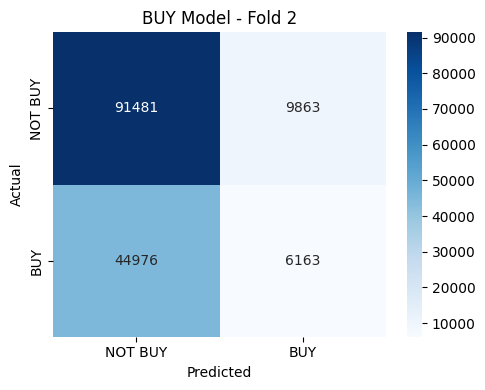

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Fold BUY terbaik
best_buy_idx = np.argmax([r["best_prec"] for r in buy_reports])

best_model = buy_models[best_buy_idx]
best_fold  = folds[best_buy_idx]

val_ds = TensorDataset(
    X_tensor[best_fold["val_idx"]],
    y_buy_tensor[best_fold["val_idx"]]
)

val_loader = DataLoader(
    val_ds,
    batch_size=1024,
    shuffle=False
)

best_model.eval()

all_preds = []
all_targets = []
all_probs = []

THRESHOLD = 0.70

with torch.no_grad():

    for xb, yb in val_loader:

        xb = xb.to(device)

        logits, conf = best_model(xb)

        # probabilitas kelas BUY (kelas = 1)
        prob = torch.softmax(logits, dim=1)[:, 1]

        pred = (prob >= THRESHOLD).long()

        all_probs.extend(prob.cpu().numpy())
        all_preds.extend(pred.cpu().numpy())
        all_targets.extend(yb.numpy())

print(f"Threshold = {THRESHOLD:.2f}")
print()

print(classification_report(
    all_targets,
    all_preds,
    target_names=["NOT BUY", "BUY"],
    digits=4,
    zero_division=0
))

cm = confusion_matrix(all_targets, all_preds)

plt.figure(figsize=(5,4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["NOT BUY","BUY"],
    yticklabels=["NOT BUY","BUY"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(f"BUY Model - Fold {best_fold['fold']}")
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import roc_auc_score

best_model.eval()

all_probs = []
all_targets = []

with torch.no_grad():

    for xb, yb in val_loader:

        xb = xb.to(device)

        logits, _ = best_model(xb)

        # probabilitas kelas BUY/SELL
        probs = torch.softmax(logits, dim=1)[:, 1]

        all_probs.extend(probs.cpu().numpy())
        all_targets.extend(yb.numpy())

auc = roc_auc_score(all_targets, all_probs)

print(f"ROC AUC = {auc:.4f}")

ROC AUC = 0.5597


Threshold = 0.70

              precision    recall  f1-score   support

    NOT SELL     0.6728    1.0000    0.8044    102588
        SELL     0.0000    0.0000    0.0000     49895

    accuracy                         0.6728    152483
   macro avg     0.3364    0.5000    0.4022    152483
weighted avg     0.4526    0.6728    0.5412    152483



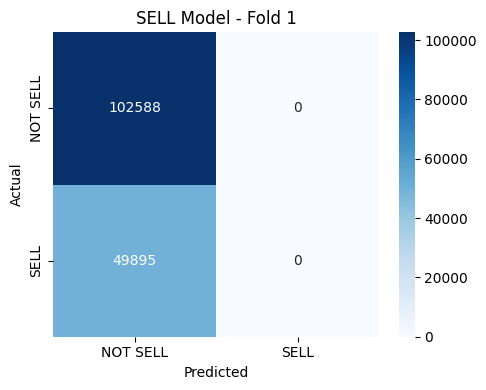

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Fold SELL terbaik
best_sell_idx = np.argmax([r["best_prec"] for r in sell_reports])

best_model = sell_models[best_sell_idx]
best_fold  = folds[best_sell_idx]

val_ds = TensorDataset(
    X_tensor[best_fold["val_idx"]],
    y_sell_tensor[best_fold["val_idx"]]
)

val_loader = DataLoader(
    val_ds,
    batch_size=1024,
    shuffle=False
)

best_model.eval()

all_probs = []
all_preds = []
all_targets = []

THRESHOLD = 0.70

with torch.no_grad():

    for xb, yb in val_loader:

        xb = xb.to(device)

        logits, conf = best_model(xb)

        # probabilitas kelas SELL (kelas = 1)
        prob = torch.softmax(logits, dim=1)[:, 1]

        pred = (prob >= THRESHOLD).long()

        all_probs.extend(prob.cpu().numpy())
        all_preds.extend(pred.cpu().numpy())
        all_targets.extend(yb.numpy())

print(f"Threshold = {THRESHOLD:.2f}\n")

print(classification_report(
    all_targets,
    all_preds,
    target_names=["NOT SELL", "SELL"],
    digits=4,
    zero_division=0
))

cm = confusion_matrix(all_targets, all_preds)

plt.figure(figsize=(5,4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["NOT SELL", "SELL"],
    yticklabels=["NOT SELL", "SELL"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(f"SELL Model - Fold {best_fold['fold']}")
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import roc_auc_score

best_model.eval()

all_probs = []
all_targets = []

with torch.no_grad():

    for xb, yb in val_loader:

        xb = xb.to(device)

        logits, _ = best_model(xb)

        # probabilitas kelas BUY/SELL
        probs = torch.softmax(logits, dim=1)[:, 1]

        all_probs.extend(probs.cpu().numpy())
        all_targets.extend(yb.numpy())

auc = roc_auc_score(all_targets, all_probs)

print(f"ROC AUC = {auc:.4f}")

ROC AUC = 0.5464


In [ ]:
# B1 + B2 — Threshold sweep untuk BUY dan SELL model terbaik
from sklearn.metrics import precision_score
import numpy as np

# Pakai fold terakhir sebagai evaluasi
best_buy_model  = buy_models[-1]
best_sell_model = sell_models[-1]
val_idx = folds[-1]["val_idx"]

# C2 — regime filter pada val set
regime_ok = regime_mask(natr_tensor[val_idx], adx_tensor[val_idx]).numpy()

val_ds   = TensorDataset(X_tensor[val_idx], y_tensor[val_idx])
val_loader = DataLoader(val_ds, batch_size=1024, shuffle=False)

# Kumpulkan logits dari kedua model
all_buy_probs, all_sell_probs, all_targets_list = [], [], []

best_buy_model.eval()
best_sell_model.eval()
with torch.no_grad():
    for xb, yb in val_loader:
        xb = xb.to(device)
        logits_buy,  _ = best_buy_model(xb)
        logits_sell, _ = best_sell_model(xb)
        all_buy_probs.append(torch.softmax(logits_buy, dim=1)[:, 1].cpu())
        all_sell_probs.append(torch.softmax(logits_sell, dim=1)[:, 1].cpu())
        all_targets_list.append(yb)

buy_probs   = torch.cat(all_buy_probs).numpy()
sell_probs  = torch.cat(all_sell_probs).numpy()
targets     = torch.cat(all_targets_list).numpy()

# Binarize targets untuk evaluasi
t_buy  = (targets == 1).astype(int)
t_sell = (targets == 2).astype(int)

print(f"{'THR_BUY':>8} {'THR_SELL':>9} {'Prec_BUY':>9} {'Prec_SELL':>10} {'N_BUY':>7} {'N_SELL':>7}")
print("-" * 58)

best_combo = None
best_avg   = 0.0

for thr_buy in [0.45, 0.50, 0.55, 0.60, 0.65, 0.70]:
    for thr_sell in [0.45, 0.50, 0.55, 0.60, 0.65, 0.70]:
        for margin in [0.10, 0.15, 0.20]:
            # B1: prob threshold
            pred_buy  = (buy_probs  > thr_buy) .astype(int)
            pred_sell = (sell_probs > thr_sell).astype(int)

            # B2: zona abu-abu — margin tipis antara buy vs sell prob
            thin = np.abs(buy_probs - sell_probs) < margin
            pred_buy[thin]  = 0
            pred_sell[thin] = 0

            # C2: regime filter
            pred_buy[~regime_ok]  = 0
            pred_sell[~regime_ok] = 0

            # Hindari konflik: kalau dua-duanya 1, ambil yang lebih tinggi
            conflict = (pred_buy == 1) & (pred_sell == 1)
            pred_buy[conflict  & (buy_probs < sell_probs)] = 0
            pred_sell[conflict & (buy_probs >= sell_probs)] = 0

            n_buy  = pred_buy.sum()
            n_sell = pred_sell.sum()

            if n_buy < 5 or n_sell < 5:
                continue

            prec_buy  = precision_score(t_buy,  pred_buy,  zero_division=0)
            prec_sell = precision_score(t_sell, pred_sell, zero_division=0)
            avg       = (prec_buy + prec_sell) / 2

            if avg > best_avg:
                best_avg   = avg
                best_combo = (thr_buy, thr_sell, margin, prec_buy, prec_sell, n_buy, n_sell)

            if thr_buy == thr_sell and margin == 0.15:
                print(f"  {thr_buy:.2f}     {thr_sell:.2f}    {prec_buy:.4f}     {prec_sell:.4f}    {n_buy:5d}  {n_sell:5d}")

if best_combo:
    tb, ts, mg, pb, ps, nb_, ns = best_combo
    print(f"\n🏆 BEST COMBO: thr_buy={tb:.2f} thr_sell={ts:.2f} margin={mg:.2f}")
    print(f"   Prec BUY={pb:.4f}  Prec SELL={ps:.4f}  avg={best_avg:.4f}")
    print(f"   Sinyal BUY={nb_:,}  SELL={ns:,}")
    BUY_THR  = tb
    SELL_THR = ts
    MARGIN   = mg


 THR_BUY  THR_SELL  Prec_BUY  Prec_SELL   N_BUY  N_SELL
----------------------------------------------------------
  0.45     0.45    0.3786     0.2913     1157   5283
  0.50     0.50    0.3786     0.3101     1157   4289
  0.55     0.55    0.3799     0.3293     1145   2833
  0.60     0.60    0.3903     0.4000     1012    230

🏆 BEST COMBO: thr_buy=0.65 thr_sell=0.60 margin=0.20
   Prec BUY=0.3724  Prec SELL=0.5135  avg=0.4430
   Sinyal BUY=196  SELL=37


## 11. Live Prediction

In [17]:
import joblib, time
import torch, torch.nn.functional as F

SYMBOL        = "XAUUSD"
TIMEFRAME_INF = mt5.TIMEFRAME_M5
WINDOW_INF    = 96

BUY_THR = 0.55
SELL_THR = 0.57
MARGIN = 0.10

scaler_X = joblib.load("scaler.pkl")

# Load model terbaik (fold terakhir)
inf_buy_model  = HighPrecisionTradingModel(n_features=N_FEATURES, n_classes=2).to(device)
inf_sell_model = HighPrecisionTradingModel(n_features=N_FEATURES, n_classes=2).to(device)
inf_buy_model.load_state_dict( torch.load("buy_model_fold2.pth",  map_location=device))
inf_sell_model.load_state_dict(torch.load("sell_model_fold2.pth", map_location=device))
inf_buy_model.eval()
inf_sell_model.eval()

def get_latest_data(n=700):
    rates = mt5.copy_rates_from_pos(SYMBOL, TIMEFRAME_INF, 0, n)
    if rates is None:
        raise ValueError("Tidak ada data dari MT5")
    df_live = pd.DataFrame(rates)
    df_live = create_features(df_live)
    if len(df_live) < WINDOW_INF:
        raise ValueError(f"Data terlalu sedikit: {len(df_live)}")
    return df_live.copy()[:-1]

def prepare_input(df_live):
    feats  = df_live[FEATURE_COLUMNS].values[-WINDOW_INF:]
    feats  = scaler_X.transform(feats)
    tensor = torch.tensor(
        feats.reshape(1, WINDOW_INF, N_FEATURES), dtype=torch.float32
    ).to(device)
    return tensor

def predict_v2():
    df_live = get_latest_data()

    # C2 — Regime filter: cek kondisi pasar terakhir
    last      = df_live.iloc[-1]
    last_natr = last["natr"]
    last_adx  = last.get("adx", last.get("atr_ratio", 99))

    NATR_MIN_INFERENCE = 0.0010

    if last_natr < NATR_MIN_INFERENCE:
        print(f"⏸ SKIP — NATR={last_natr:.5f} terlalu rendah (sideways)")
        return None, 0

    if last_adx < ADX_MIN:
        print(f"⏸ SKIP — ADX={last_adx:.2f} terlalu rendah (tidak trending)")
        return None, 0

    x = prepare_input(df_live)

    with torch.no_grad():
        logits_buy,  conf_buy  = inf_buy_model(x)
        logits_sell, conf_sell = inf_sell_model(x)

    prob_buy  = torch.softmax(logits_buy,  dim=1)[0, 1].item()
    prob_sell = torch.softmax(logits_sell, dim=1)[0, 1].item()
    conf_b    = torch.sigmoid(conf_buy).item()
    conf_s    = torch.sigmoid(conf_sell).item()

    print(f"📊 prob_buy={prob_buy:.3f} (conf={conf_b:.3f})  "
          f"prob_sell={prob_sell:.3f} (conf={conf_s:.3f})")

    # B1 — threshold gate
    signal_buy  = (prob_buy  > BUY_THR)  and (conf_b > 0.50)
    signal_sell = (prob_sell > SELL_THR) and (conf_s > 0.50)

    # B2 — zona abu-abu: margin terlalu tipis → HOLD
    if abs(prob_buy - prob_sell) < MARGIN:
        print(f"⚪ HOLD — margin tipis ({abs(prob_buy-prob_sell):.3f} < {MARGIN})")
        return 0, max(prob_buy, prob_sell)

    # Konflik: dua-duanya tinggi → ambil yang lebih yakin
    if signal_buy and signal_sell:
        signal_buy  = prob_buy >= prob_sell
        signal_sell = not signal_buy

    if signal_buy:
        print(f"📈 BUY  — prob={prob_buy:.3f}  conf={conf_b:.3f}")
        return 1, prob_buy
    elif signal_sell:
        print(f"📉 SELL — prob={prob_sell:.3f}  conf={conf_s:.3f}")
        return 2, prob_sell
    else:
        print(f"🟡 HOLD — prob_buy={prob_buy:.3f} prob_sell={prob_sell:.3f}")
        return 0, max(prob_buy, prob_sell)


In [18]:
import warnings
from pandas.errors import PerformanceWarning

warnings.filterwarnings("ignore", category=PerformanceWarning)

In [ ]:
LABELS   = {0: "🟡 HOLD", 1: "📈 BUY", 2: "📉 SELL"}
index_i  = 1

while True:
    try:
        signal, confidence = predict_v2()
        if signal is not None:
            print(f"#{index_i} | {LABELS[signal]} | conf={confidence*100:.2f}%\n")
        time.sleep(30)
    except Exception as e:
        print(f"Error: {e}")
        time.sleep(5)
    index_i += 1


📊 prob_buy=0.296 (conf=0.873)  prob_sell=0.424 (conf=0.843)
🟡 HOLD — prob_buy=0.296 prob_sell=0.424
#1 | 🟡 HOLD | conf=42.36%

📊 prob_buy=0.296 (conf=0.873)  prob_sell=0.424 (conf=0.843)
🟡 HOLD — prob_buy=0.296 prob_sell=0.424
#2 | 🟡 HOLD | conf=42.36%

📊 prob_buy=0.296 (conf=0.873)  prob_sell=0.424 (conf=0.843)
🟡 HOLD — prob_buy=0.296 prob_sell=0.424
#3 | 🟡 HOLD | conf=42.36%



In [ ]:
import torch
import torch.nn.functional as F

def predict_ensemble(input_tensor,
                     models,
                     conf_threshold=0.55,
                     vote_threshold=0.5):
    """
    Ensemble prediction dengan confidence gate.
    Hanya keluarkan sinyal BUY/SELL jika:
      1. conf_prob >= conf_threshold
      2. Mayoritas model setuju (vote_threshold)
    """
    all_probs = []
    all_confs = []

    for m in models:
        m.eval()
        with torch.no_grad():
            logits, conf = m(input_tensor)          # FIX: unpack tuple
            probs        = F.softmax(logits, dim=1) # (B, 3)
            conf_prob    = torch.sigmoid(conf)      # (B, 1), range 0–1
            all_probs.append(probs)
            all_confs.append(conf_prob)

    # Rata-rata probabilitas & confidence dari semua fold model
    mean_probs = torch.stack(all_probs).mean(dim=0)  # (B, 3)
    mean_confs = torch.stack(all_confs).mean(dim=0)  # (B, 1)

    preds     = mean_probs.argmax(dim=1)             # (B,)
    conf_prob = mean_confs.squeeze()                  # (B,)

    # Confidence gate: prediksi jadi HOLD jika model tidak yakin
    preds = preds.clone()
    preds[conf_prob < conf_threshold] = 0

    return preds, mean_probs, conf_prob
pred_no = 129
predictions, probabilities, conf_prob = predict_ensemble(X_tensor[-pred_no:-pred_no+1].to(device), HighPrecisionTradingModel, paths, device, threshold=0.30)
print("predictions:", predictions)
print("probabilities:", probabilities)
print(X_tensor[-3:].shape)

predictions: tensor([0])
probabilities: tensor([[0.4574, 0.2773, 0.2653]], device='cuda:0')
torch.Size([3, 128, 57])


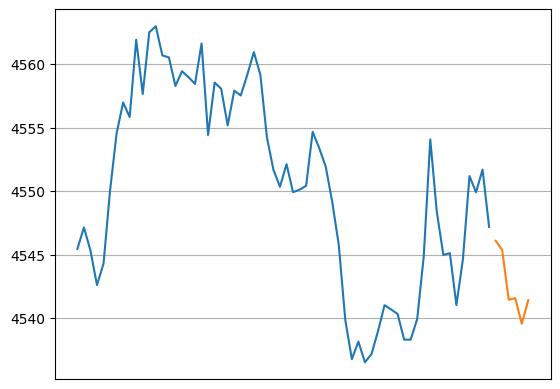

In [ ]:
range_history = 64 * pred_no

# 1. Ambil batasan masa lalunya dulu
df_historical = df["close"].iloc[-range_history:]

# 2. Ambil 64 data pertama dari potongan tersebut
df_plot = df_historical.iloc[:64]

df_actual = df_historical.iloc[64:64+6]

# Atau jika ingin mengambil 64 data terakhir dari potongan tersebut:
# df_plot = df_historical.tail(64)

plt.plot(df_plot)
plt.plot(df_actual)
plt.grid(True)
# Supaya x-axis nya tidak penuh angka timestamp mentah
plt.xticks(rotation=45) 
plt.show()

In [ ]:
X_lgb = X[:, -1, :]

In [ ]:
print(np.unique(y))
print(y.shape)

[0 1 2]
(457277,)


In [ ]:
y_buy = (y == 1).astype(np.int32)

model = lgb.LGBMClassifier(
    objective="binary",
    metric="auc",
    n_estimators=500,
    learning_rate=0.03,
    random_state=42
)

model.fit(X_lgb, y_buy)

[LightGBM] [Info] Number of positive: 151042, number of negative: 306235
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.067611 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 18521
[LightGBM] [Info] Number of data points in the train set: 457277, number of used features: 84
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.330307 -> initscore=-0.706795
[LightGBM] [Info] Start training from score -0.706795


,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,learning_rate,0.03
,n_estimators,500
,subsample_for_bin,200000
,objective,'binary'
,class_weight,None
,min_split_gain,0.0
,min_child_weight,0.001
,min_child_samples,20


In [ ]:
importance = pd.DataFrame({
    "feature": FEATURE_COLUMNS,
    "importance": model.booster_.feature_importance(
        importance_type="gain"
    )
})

importance = importance.sort_values(
    "importance",
    ascending=False
)

import pandas as pd

pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)

print(importance)

                    feature    importance
58                 hour_cos  51808.343715
21                     natr  37315.451903
82          volume_momentum  30427.348621
78          volatility_rank  30270.098581
24                atr_ratio  25922.548263
57                 hour_sin  19762.207793
14                ema50_200  19095.753509
28                     rv48  16115.242473
61                      adx  11732.036273
80            breakout_down  11530.080777
49          valid_scalp_fvg  11369.970458
45    volume_zscore_modular  11206.351513
81        price_position200  10721.984065
50  valid_scalp_bearish_fvg  10519.665955
79              breakout_up  10369.212497
69               atr_expand  10277.799238
65                   ret_96   9098.481722
9               ema200_dist   8884.889803
34              swing_range   8774.751225
12             ema200_slope   8279.418761
27                     rv24   8204.167924
56              sesi_golden   8060.230754
73                 bb_width   7942

In [ ]:
y_sell = (y == 2).astype(np.int32)

model.fit(X_lgb, y_sell)

[LightGBM] [Info] Number of positive: 147478, number of negative: 309799
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.068531 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 18521
[LightGBM] [Info] Number of data points in the train set: 457277, number of used features: 84
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.322513 -> initscore=-0.742245
[LightGBM] [Info] Start training from score -0.742245


,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,learning_rate,0.03
,n_estimators,500
,subsample_for_bin,200000
,objective,'binary'
,class_weight,None
,min_split_gain,0.0
,min_child_weight,0.001
,min_child_samples,20


In [ ]:
importance = pd.DataFrame({
    "feature": FEATURE_COLUMNS,
    "importance": model.booster_.feature_importance(
        importance_type="gain"
    )
})

importance = importance.sort_values(
    "importance",
    ascending=False
)

print(importance)

                    feature    importance
58                 hour_cos  51318.038064
78          volatility_rank  34774.475275
45    volume_zscore_modular  28294.574435
24                atr_ratio  23685.609004
21                     natr  18864.122781
14                ema50_200  18662.003837
57                 hour_sin  18275.677640
50  valid_scalp_bearish_fvg  15143.041141
28                     rv48  14407.659444
79              breakout_up  10362.420904
61                      adx  10152.553791
12             ema200_slope   9986.323464
49          valid_scalp_fvg   9859.366547
34              swing_range   9716.617052
65                   ret_96   9619.477572
22               volatility   9141.263898
26                     rv12   9105.197512
82          volume_momentum   8988.473880
73                 bb_width   8735.944700
9               ema200_dist   7805.232613
69               atr_expand   7751.731277
81        price_position200   7743.375264
54               sesi_eropa   7376

In [ ]:
import matplotlib.pyplot as plt

importance = importance.head(30)

plt.figure(figsize=(10,10))
plt.barh(
    importance["feature"],
    importance["importance"]
)
plt.gca().invert_yaxis()
plt.show()